# Monthly Price decomposition — Density (den) path · rolling year-over-year

**Fitness = firm-count log growth; trait = firm count $n$; Olley–Pakes parallel of the inc path with the firm count in place of sales.** Selection is the per-year relative drift of the *experienced density* (the size-biased mean firm count $\sum n_j^2/N$): negative ⇒ small parishes out-grow large ones (firm mass dispersing), exactly zero under Gibrat growth. Because firm counts are a smooth stock, the den series is small and stable — firm registrations kept growing even through 2020, so its COVID dip is far milder than pop/inc. See the closing note for why the den magnitudes are so small.

In [1]:
# ==============================================================================
# MONTHLY PRICE DECOMPOSITION -- rolling 12-month (year-over-year) time series
# ------------------------------------------------------------------------------
# Same engine + hierarchy (parish < canton < province + country rollup) as the
# quarterly notebook, read at the MONTHLY grain from the driver's ROLLING
# run:  results/decomposition/monthly_rolling12_2017_2023/
# Each window compares a month to the SAME month one year earlier (2019M04 vs
# 2020M04, ...), advancing one month at a time -> 72 points, 2018M01 .. 2023M12.
# Because both ends are the same calendar month, SEASONALITY CANCELS and every
# term is a genuine PER-YEAR rate (elapsed = 1 yr; no 1/12 blow-up). A point
# dated "Apr '20" is the 12-month change ending April 2020.
#
# This notebook covers ONE decomposition path; set PATH below. The three path
# notebooks share these cells verbatim -- only PATH differs:
#   pop  firm-count growth (fitness) x log(real sales)  (trait)  [rebalanced Price]
#   inc  real-sales growth (fitness) x real-sales level (trait)  [Olley-Pakes]
#   den  firm-count growth (fitness) x firm count       (trait)  [Olley-Pakes]
# ==============================================================================
import calendar
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PATH = "den"     # <-- the only line that differs between the three notebooks

# The project root is the folder that holds ecuador_price/ (this notebook lives in notebooks/).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "ecuador_price").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
from ecuador_price import decomposition as dec, paths, style
style.apply()                      # the project's fonts and colours

MASTER_DIR = paths.decomposition_run("monthly_rolling12_2017_2023")
PLOTS_DIR = MASTER_DIR / "plots"
PLOTS_DIR.mkdir(exist_ok=True)

# Per-path labels/colours used by every figure below.
PATH_META = {
    "pop": dict(name="Population path",
                fitness="firm-count growth  n'/n", trait="log(real total sales)",
                trans="Transmission  (within-region real-sales growth)",
                sel="Selection  (spatial sorting of firm formation)",
                unit="log points"),
    "inc": dict(name="Income path",
                fitness="real-sales log growth", trait="real-sales level",
                trans="Transmission  (within-region real-sales growth)",
                sel="Selection  (sales reallocated toward growing regions)",
                unit="log points"),
    "den": dict(name="Density path",
                fitness="firm-count log growth", trait="firm count  n",
                trans="Transmission  (within-region firm-count growth)",
                sel="Selection  (experienced-density drift)",
                unit="percentage"),
}
META = PATH_META[PATH]
TRANS_COLOR, SEL_COLOR = style.RED, style.BLUE
STRIDE = 3   # label every 3rd month so the 72-point axis stays legible

summary = pd.read_csv(MASTER_DIR / "decomposition_summary.csv")
df = summary[summary["path"] == PATH].copy()


def month_label(period):                       # "2020M04" -> "Apr '20"
    return f"{calendar.month_abbr[int(period[5:])]} '{period[2:4]}"


# The 72 rolling YoY windows in chronological order, each DATED AT ITS END month
# (so "Apr '20" is the Apr 2019 -> Apr 2020 change). Months are zero padded, so
# a plain string sort on initial_period is already chronological.
ts = (df[df["window_type"] == "step"]
      .sort_values("initial_period").reset_index(drop=True))
labels = [month_label(p) for p in ts["final_period"]]
xs = list(range(len(ts)))

# COVID: the YoY window ending Apr 2020 is the onset trough; every window ending
# from Apr 2020 to Apr 2021 still straddles the 2020 lockdown -> shade that band.
covid_pos = int(ts.index[ts["final_period"] == "2020M04"][0])
covid_end = int(ts.index[ts["final_period"] == "2021M04"][0])

head = df[df["window_type"] == "headline"].iloc[0]
print(f"PATH = {PATH!r}  ({META['name']})")
print(f"  fitness = {META['fitness']}   |   trait = {META['trait']}")
print(f"  {len(ts)} rolling 12-month windows, "
      f"{ts['final_period'].iloc[0]} .. {ts['final_period'].iloc[-1]}")
print()
print(f"season-matched headline {head['initial_period']}->{head['final_period']} "
      f"(per year over {head['elapsed_years']:.0f} yr):")
print(f"  selection_total = {head['selection_total']:+.4f}")
print(f"  transmission    = {head['transmission']:+.4f}")
print(f"  delta_trait/yr  = {head['delta_trait_per_year']:+.4f}")
print()
print("COVID onset window (ends Apr 2020):")
c = ts.loc[covid_pos]
print(f"  {c['initial_period']}->{c['final_period']}: "
      f"selection {c['selection_total']:+.3f}, transmission {c['transmission']:+.3f} "
      f"({np.expm1(c['transmission']):+.0%} YoY)")


PATH = 'den'  (Density path)
  fitness = firm-count log growth   |   trait = firm count  n
  72 rolling 12-month windows, 2018M01 .. 2023M12

season-matched headline 2017M01->2023M01 (per year over 6 yr):
  selection_total = -0.0095
  transmission    = +0.0974
  delta_trait/yr  = +0.0879

COVID onset window (ends Apr 2020):
  2019M04->2020M04: selection +0.016, transmission +0.042 (+4% YoY)


saved -> monthly_timeseries_den.png


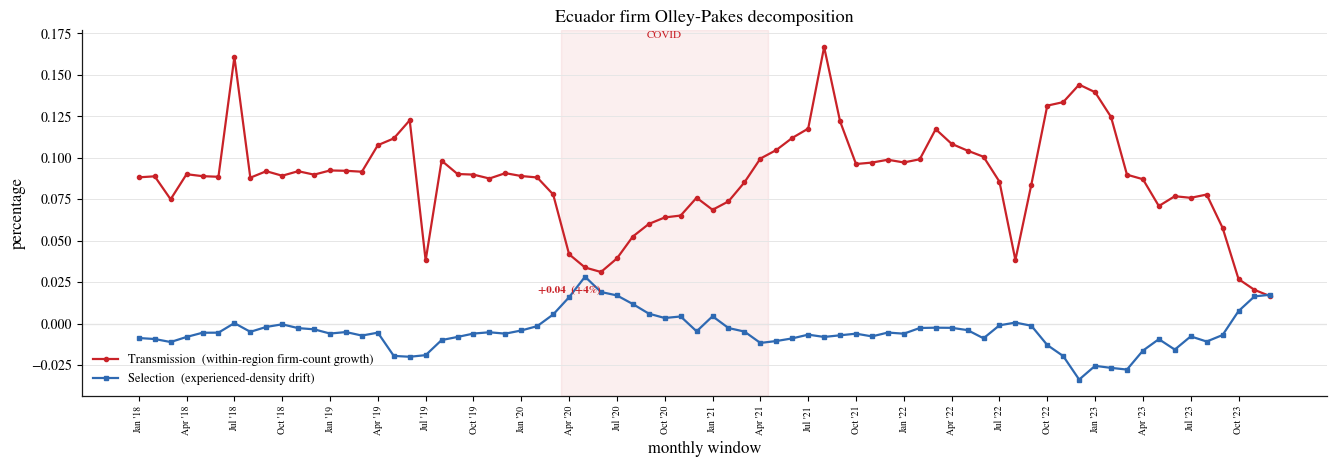

In [2]:
# ==============================================================================
# Combined rolling-YoY time series: selection + transmission on one calendar axis.
# ------------------------------------------------------------------------------
# Deseasonalised per-year rates. The shaded band marks the YoY windows that
# straddle the 2020 lockdown; the trough at Apr 2020 is annotated.
# ==============================================================================
fig, ax = plt.subplots(figsize=(13.5, 4.8))
ax.axhline(0, color="0.7", lw=0.8, zorder=1)
ax.axvspan(covid_pos - 0.5, covid_end + 0.5, color=style.RED, alpha=0.07, zorder=0)
ax.plot(xs, ts["transmission"], marker="o", ms=3, lw=1.6, color=TRANS_COLOR,
        label=META["trans"], zorder=3)
ax.plot(xs, ts["selection_total"], marker="s", ms=3, lw=1.6, color=SEL_COLOR,
        label=META["sel"], zorder=3)
ax.text((covid_pos + covid_end) / 2, ax.get_ylim()[1], "COVID",
        ha="center", va="top", fontsize=8, color=style.RED)

v = ts.loc[covid_pos, "transmission"]
ax.annotate(f"{v:+.2f}  ({np.expm1(v):+.0%})", (covid_pos, v),
            textcoords="offset points", xytext=(0, -28), ha="center",
            fontsize=8, color=style.RED, fontweight="bold")

ax.set_xticks(xs[::STRIDE]); ax.set_xticklabels(labels[::STRIDE], rotation=90, fontsize=7)
ax.set_ylabel(META["unit"]); ax.set_xlabel("monthly window")
ax.set_title(f"Ecuador firm Olley-Pakes decomposition")
ax.grid(axis="y", color="0.9", lw=0.7)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(loc="lower left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"monthly_timeseries_{PATH}.png", dpi=200, bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"monthly_timeseries_{PATH}.pdf", bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"monthly_timeseries_{PATH}.svg", bbox_inches="tight")
print(f"saved -> monthly_timeseries_{PATH}.png")
plt.show()


## Selection — experienced-density drift

Selection = per-year relative drift of the size-biased mean firm count (the parish size the *average firm* sits in). **Negative ⇒ small parishes out-grow large ones (firm mass dispersing); ≈ 0 ⇒ Gibrat (scale-free) growth.** It stays tiny throughout — Ecuadorian firm formation is close to scale-free.

saved -> monthly_selection_den.png


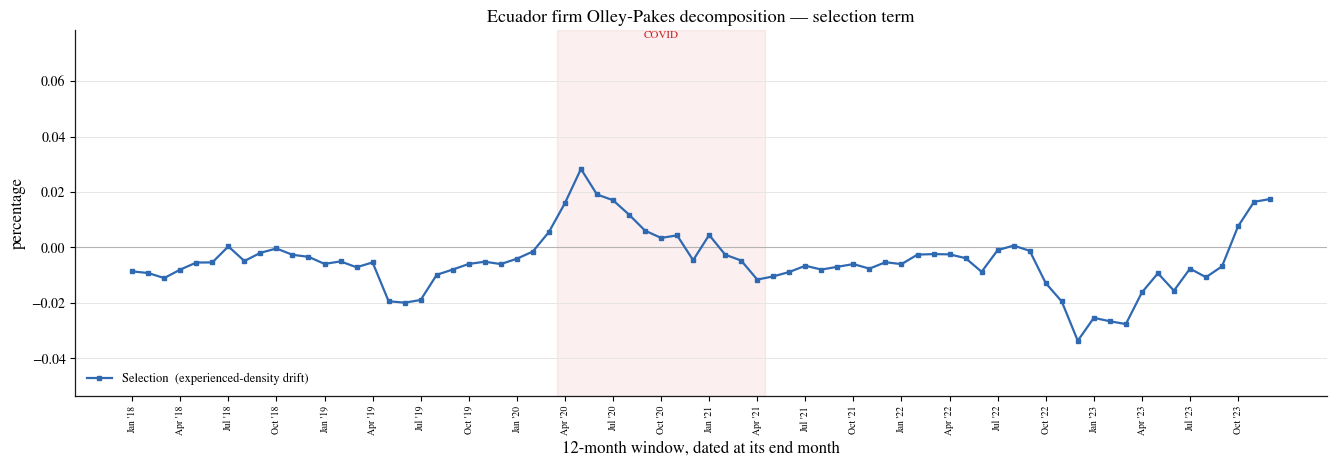

In [3]:
# selection-only figure -- selection at its own scale, COVID band shaded.
sel = ts["selection_total"].values
lo, hi = float(np.nanmin(sel)) - 0.02, float(np.nanmax(sel)) + 0.05

fig, ax = plt.subplots(figsize=(13.5, 4.8))
ax.axhline(0, color="0.7", lw=0.8)
ax.axvspan(covid_pos - 0.5, covid_end + 0.5, color=style.RED, alpha=0.07)
ax.plot(xs, sel, marker="s", ms=3, lw=1.6, color=SEL_COLOR, label=META["sel"])
ax.text((covid_pos + covid_end) / 2, hi, "COVID",
        ha="center", va="top", fontsize=8, color=style.RED)
ax.set_ylim(lo, hi)
ax.set_xticks(xs[::STRIDE]); ax.set_xticklabels(labels[::STRIDE], rotation=90, fontsize=7)
ax.set_ylabel(META["unit"]); ax.set_xlabel("12-month window, dated at its end month")
ax.set_title(f"Ecuador firm Olley-Pakes decomposition — selection term")
ax.grid(axis="y", color="0.9", lw=0.7)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(loc="lower left", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"monthly_selection_{PATH}.png", dpi=200, bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"monthly_selection_{PATH}.pdf", bbox_inches="tight")
print(f"saved -> monthly_selection_{PATH}.png")
plt.show()


In [4]:
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# Shared styling
# ==============================================================================
plt.rcParams.update({
    "font.family":      "STIXGeneral",
    "mathtext.fontset": "cm",
    "axes.titlesize":   14,
    "axes.labelsize":   13,
    "xtick.labelsize":  11,
    "ytick.labelsize":  11,
    "axes.linewidth":   1.1,
    "axes.edgecolor":   "black",
})

COVID_C = style.RED


def get_ts(path):
    """Chronological step windows for one path + the two COVID band indices."""
    d = (summary[(summary["path"] == path) & (summary["window_type"] == "step")]
         .sort_values("initial_period")
         .reset_index(drop=True))
    c0 = int(d.index[d["final_period"] == "2020M04"][0])   # onset trough
    c1 = int(d.index[d["final_period"] == "2021M04"][0])   # last window spanning 2020
    return d, c0, c1


# ==============================================================================
# Automatic label placement -- used by EVERY figure in this notebook
# ------------------------------------------------------------------------------
# The value labels used to sit at a fixed offset from their point, so they landed
# on top of the plotted lines, on each other, or on the "COVID" tag at the top of
# the red band. Now each label is TRIED at a handful of candidate offsets around
# its point and the least-colliding one wins. Obstacles: the plotted lines, every
# text already on the axes (the COVID tag, and any label placed before this one),
# the legend, and the axes frame itself.
# ==============================================================================
_CAND_DY = (0, 16, -16, 30, -30, 46, -46)      # vertical nudges, in points


def _bbox_overlap(a, b):
    """Overlapping area of two display-space bboxes (0 if they miss)."""
    dx = min(a.x1, b.x1) - max(a.x0, b.x0)
    dy = min(a.y1, b.y1) - max(a.y0, b.y0)
    return dx * dy if dx > 0 and dy > 0 else 0.0


def _line_points(ax):
    """Every plotted vertex, densified along each segment, in display coords."""
    out = []
    for ln in ax.get_lines():
        if ln.get_transform() is not ax.transData:      # skips axhline & friends
            continue
        xy = ln.get_xydata()
        if len(xy) < 2:
            continue
        fine = np.concatenate([xy[:-1] + f * (xy[1:] - xy[:-1])
                               for f in np.linspace(0, 1, 6)])
        out.append(ax.transData.transform(fine))
    return np.concatenate(out) if out else np.empty((0, 2))


def _place_label(ax, pos, v, text, color, ann_fs, right_only):
    """Draw one label near (pos, v), at whichever offset collides least."""
    fig = ax.figure
    fig.canvas.draw()                          # text sizes need a live renderer
    rend = fig.canvas.get_renderer()

    pts = _line_points(ax)
    obstacles = [t.get_window_extent(rend) for t in ax.texts]
    leg = ax.get_legend()
    if leg is not None:
        obstacles.append(leg.get_window_extent(rend))
    frame = ax.get_window_extent(rend)

    probe = ax.annotate(text, (pos, v), textcoords="offset points",
                        xytext=(10, 0), va="center", fontsize=ann_fs,
                        fontweight="bold", annotation_clip=False)

    def cost(bb):
        pad = bb.expanded(1.10, 1.6)           # a little breathing room
        on_line = ((pts[:, 0] > pad.x0) & (pts[:, 0] < pad.x1) &
                   (pts[:, 1] > pad.y0) & (pts[:, 1] < pad.y1)).sum()
        outside = bb.width * bb.height - _bbox_overlap(bb, frame)
        return (4.0 * on_line                                       # over a line
                + sum(_bbox_overlap(pad, ob) for ob in obstacles) / 60.0
                + outside / 30.0)                                   # off the axes

    best = None
    for dx in ((10,) if right_only else (10, -10)):
        for dy in _CAND_DY:
            probe.set_position((dx, dy))
            probe.set_ha("left" if dx > 0 else "right")
            c = cost(probe.get_window_extent(rend)) + 0.02 * abs(dy)  # stay close
            if best is None or c < best[0]:
                best = (c, dx, dy)
    probe.remove()

    _, dx, dy = best
    ax.annotate(
        text, (pos, v),
        textcoords="offset points", xytext=(dx, dy),
        ha="left" if dx > 0 else "right", va="center",
        fontsize=ann_fs, fontweight="bold", color=color, zorder=6,
        annotation_clip=False,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.80, pad=1.0),
        # hairline leader only when the label had to walk away from its point
        arrowprops=(dict(arrowstyle="-", lw=0.6, color=color, shrinkA=0, shrinkB=3)
                    if abs(dy) > 16 else None),
    )


def annotate_band_minmax(ax, d, c0, c1, col, color, ann_fs=10, right_only=False):
    """
    Label the min and max of `col` inside the COVID band, placed so the text
    clears the lines, the COVID tag and any label already on this axes.
    Call it LAST -- after the lines, the COVID tag and the legend exist.
    `right_only=True` keeps labels on the right-hand side of their point.
    """
    band = d.loc[c0:c1]
    i_min = int(band[col].idxmin())
    i_max = int(band[col].idxmax())

    points = [(i_min, float(d.loc[i_min, col]))]
    if i_max != i_min:
        points.append((i_max, float(d.loc[i_max, col])))

    for pos, v in points:
        _place_label(ax, pos, v, f"{v:+.2f} ({np.expm1(v):+.0%})",
                     color, ann_fs, right_only)


def add_headroom(ax, top=0.16, bottom=0.05):
    """Widen the y-range so the COVID tag and the labels have somewhere to go."""
    y0, y1 = ax.get_ylim()
    span = y1 - y0
    ax.set_ylim(y0 - bottom * span, y1 + top * span)


def draw_panel(ax, path, tick_stride, small=False, show_xticklabels=True,
               show_legend=True, legend_loc="upper left"):
    ann_fs, tick_fs, leg_fs = (9, 10, 9.5) if small else (10, 11, 11)

    meta = PATH_META[path]
    d, c0, c1 = get_ts(path)
    xs = list(range(len(d)))
    labels = [month_label(p) for p in d["final_period"]]

    ax.axhline(0, color="0.35", lw=1.0, alpha=0.40, zorder=1)
    ax.axvspan(c0 - 0.5, c1 + 0.5, color=COVID_C, alpha=0.08, zorder=0)

    ax.plot(xs, d["transmission"], marker="o", ms=3, lw=1.6,
            color=TRANS_COLOR, label=meta["trans"], zorder=3)
    ax.plot(xs, d["selection_total"], marker="s", ms=3, lw=1.6,
            color=SEL_COLOR, label=meta["sel"], zorder=3)

    ax.set_xticks(xs[::tick_stride])
    ax.set_xticklabels(labels[::tick_stride], rotation=90, fontsize=tick_fs)
    if not show_xticklabels:
        ax.tick_params(labelbottom=False)

    ax.set_ylabel(meta["unit"])
    ax.set_title(meta["name"].split("(")[0].strip())

    if show_legend:
        leg = ax.legend(loc=legend_loc, fontsize=leg_fs, frameon=True,
                        fancybox=False, edgecolor="black", framealpha=1.0,
                        handlelength=1.2, handletextpad=0.6,
                        borderpad=0.5, labelspacing=0.35)
        leg.get_frame().set_linewidth(0.9)

    # COVID tag and value labels go last: the placer needs the lines, the tag
    # and the legend to already be on the axes so it can dodge them.
    add_headroom(ax)
    ax.text((c0 + c1) / 2, ax.get_ylim()[1], "COVID",
            ha="center", va="top", fontsize=ann_fs,
            fontweight="bold", color=COVID_C)

    annotate_band_minmax(ax, d, c0, c1, "transmission", TRANS_COLOR, ann_fs=ann_fs)
    annotate_band_minmax(ax, d, c0, c1, "selection_total", SEL_COLOR, ann_fs=ann_fs)

saved -> monthly_timeseries_den.png


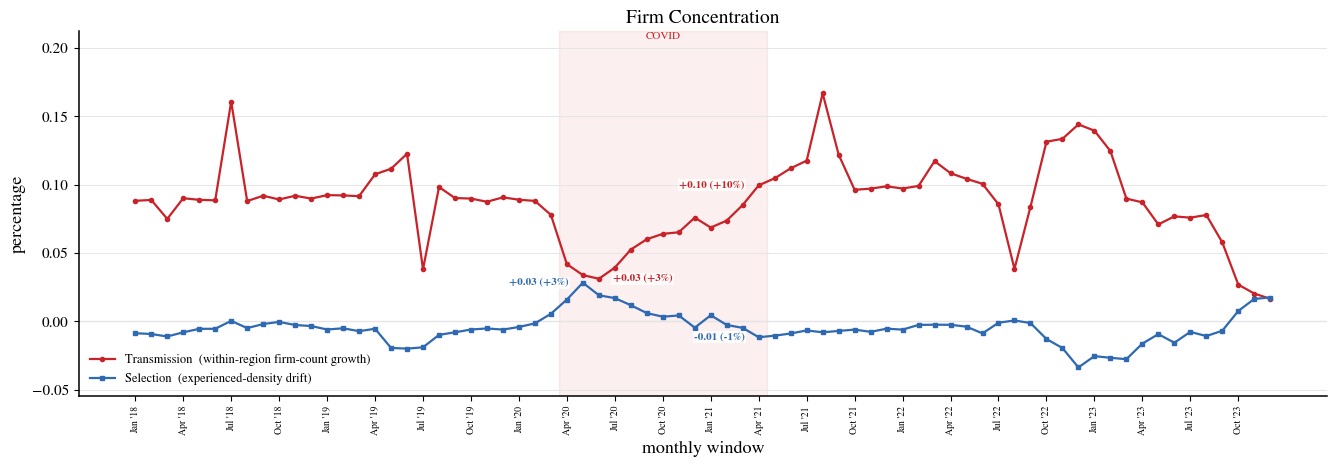

In [5]:
PATH = "den"

path = PATH   # or "pop", "inc", "den"
ts, covid_pos, covid_end = get_ts(path)
xs = list(range(len(ts)))
labels = [month_label(p) for p in ts["final_period"]]

fig, ax = plt.subplots(figsize=(13.5, 4.8))
ax.axhline(0, color="0.7", lw=0.8, zorder=1)
ax.axvspan(covid_pos - 0.5, covid_end + 0.5, color=style.RED, alpha=0.07, zorder=0)

ax.plot(xs, ts["transmission"], marker="o", ms=3, lw=1.6,
        color=TRANS_COLOR, label=META["trans"], zorder=3)
ax.plot(xs, ts["selection_total"], marker="s", ms=3, lw=1.6,
        color=SEL_COLOR, label=META["sel"], zorder=3)

ax.set_xticks(xs[::STRIDE])
ax.set_xticklabels(labels[::STRIDE], rotation=90, fontsize=7)
ax.set_ylabel(META["unit"])
ax.set_xlabel("monthly window")
ax.set_title(f"Firm Concentration")
ax.grid(axis="y", color="0.9", lw=0.7)

for s in ("top", "right"):
    ax.spines[s].set_visible(False)

ax.legend(loc="lower left", frameon=False, fontsize=9)

# COVID tag + value labels last, so the placer can dodge lines, tag and legend
add_headroom(ax)
ax.text((covid_pos + covid_end) / 2, ax.get_ylim()[1],
        "COVID",
        ha="center", va="top", fontsize=8, color=style.RED)

right_only = path in ("pop", "inc")
annotate_band_minmax(ax, ts, covid_pos, covid_end, "transmission", TRANS_COLOR, ann_fs=8, right_only=right_only)
annotate_band_minmax(ax, ts, covid_pos, covid_end, "selection_total", SEL_COLOR, ann_fs=8, right_only=right_only)

fig.tight_layout()
fig.savefig(PLOTS_DIR / f"monthly_timeseries_{PATH}.png", dpi=200, bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"monthly_timeseries_{PATH}.pdf", bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"monthly_timeseries_{PATH}.svg", bbox_inches="tight")
print(f"saved -> monthly_timeseries_{PATH}.png")
plt.show()

saved -> monthly_selection_components_den.png


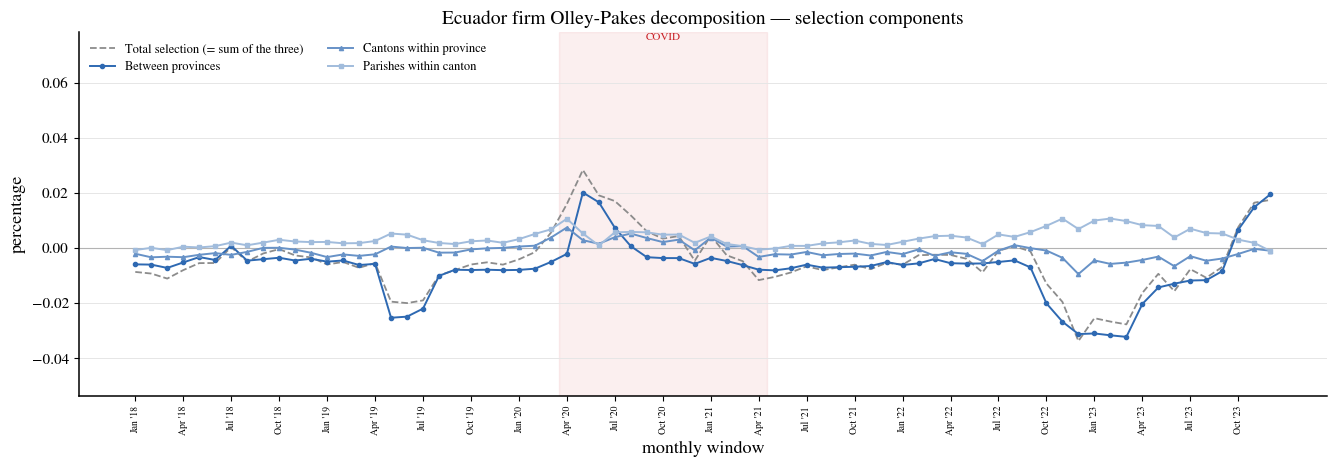

In [6]:
# selection by spatial scale -- total selection split into its three nested
# scales (they sum to the total by construction):
#   between provinces + cantons within province + parishes within canton = total
COMPONENTS = [
    ("sel_between_provinces",      style.BLUE, "o", "Between provinces"),
    ("sel_canton_within_province", style.SCALE["canton"], "^", "Cantons within province"),
    ("sel_parish_within_canton",   style.SCALE["parish"], "s", "Parishes within canton"),
]
vals = ts[[c for c, *_ in COMPONENTS] + ["selection_total"]].values
lo, hi = float(np.nanmin(vals)) - 0.02, float(np.nanmax(vals)) + 0.05

fig, ax = plt.subplots(figsize=(13.5, 4.8))
ax.axhline(0, color="0.7", lw=0.8)
ax.axvspan(covid_pos - 0.5, covid_end + 0.5, color=style.RED, alpha=0.07)
ax.plot(xs, ts["selection_total"], lw=1.3, ls="--", color="0.55",
        label="Total selection (= sum of the three)")
for col, color, mk, lab in COMPONENTS:
    ax.plot(xs, ts[col], marker=mk, ms=3, lw=1.4, color=color, label=lab)
ax.text((covid_pos + covid_end) / 2, hi, "COVID",
        ha="center", va="top", fontsize=8, color=style.RED)
ax.set_ylim(lo, hi)
ax.set_xticks(xs[::STRIDE]); ax.set_xticklabels(labels[::STRIDE], rotation=90, fontsize=7)
ax.set_ylabel(META["unit"]); ax.set_xlabel("monthly window")
ax.set_title(f"Ecuador firm Olley-Pakes decomposition — selection components")
ax.grid(axis="y", color="0.9", lw=0.7)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(loc="upper left", frameon=False, fontsize=9, ncol=2)
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"monthly_selection_components_{PATH}.png", dpi=200, bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"monthly_selection_components_{PATH}.pdf", bbox_inches="tight")
print(f"saved -> monthly_selection_components_{PATH}.png")
plt.show()


## Why den selection ≈ 0 — and what the parish scatter really shows

The **same** per-parish firm-count growth (y-axis) against two notions of 'size': **firm count** (den's axis, left) and **log sales** (pop's axis, right). Both clouds are **near-flat** ($|r| < 0.15$): at the parish scale, firm-count growth is roughly **independent of size on either axis** — **near-Gibrat** — which is exactly why den selection is tiny.

This also *corrects* a too-simple reading. The negative **pop** selection is **not** a strong raw parish-level 'firms grow where sales are low' correlation — that slope is faint here. It lives almost entirely **between provinces**: in the components plot `sel_between_provinces` ≈ −0.037 of the −0.043 total, while *parishes-within-canton* is ≈ 0 (slightly **positive**). So the catch-up is a **coarse, province-scale** effect (low-sales provinces add firms faster than high-sales ones) that a within-country parish scatter cannot display. Point size ∝ initial firm count — the covariance is firm-share-weighted, so the big points dominate. Two clean non-COVID year-over-year windows confirm the flat parish-level pattern is stable.

saved -> den_gibrat_scatter.png


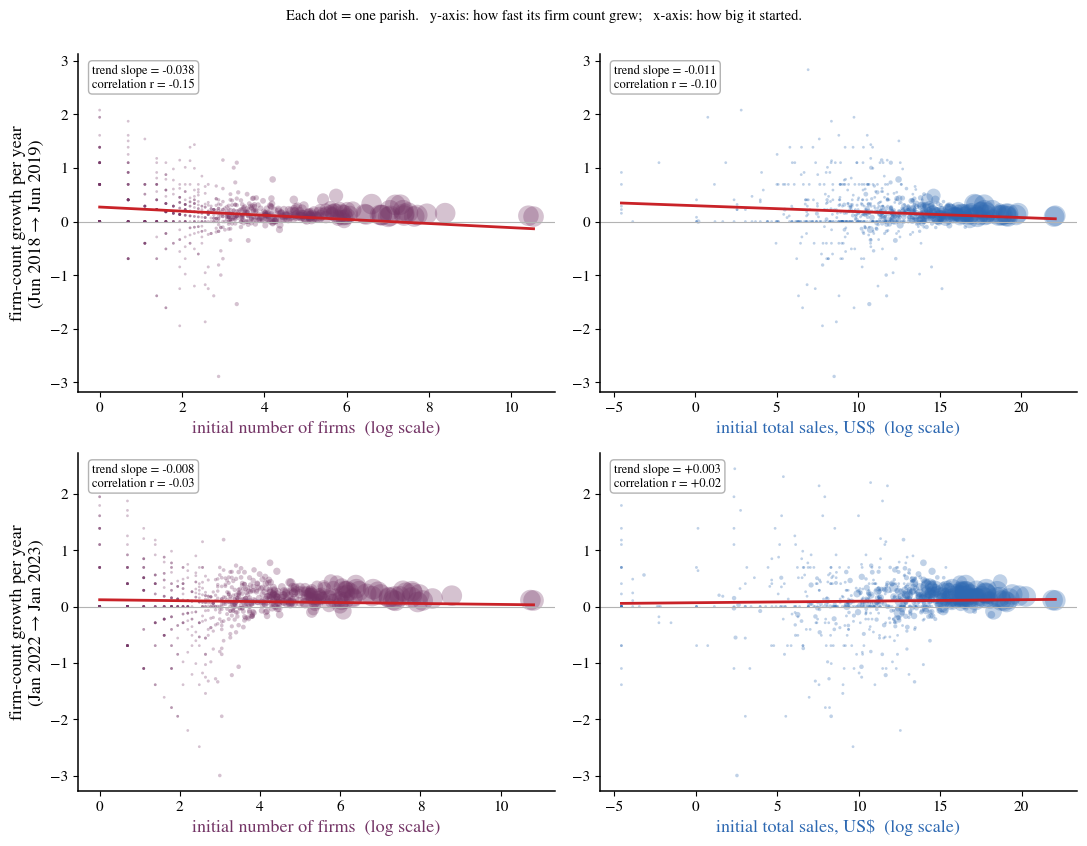

In [7]:
# ==============================================================================
# WHY den SELECTION IS NEAR ZERO -- firm-count growth vs size, two "size" axes.
# ------------------------------------------------------------------------------
# den selection = cov(firm-count growth, FIRM COUNT)/mu ~ 0  <=>  growth rate is
# ~independent of firm-count size  <=>  near-Gibrat. pop selection = cov(firm-
# count growth, LOG SALES) < 0  <=>  firms grow where SALES start low. SAME
# growth on the y-axis, two different size axes on the x -> the flat-vs-negative
# contrast. Rebuilds per-parish (firms, sales) from the engine module for two
# clean non-COVID year-over-year windows (the summary CSV has no cross-section).
# ==============================================================================
_mon = dec.monthly_table(dec.load_real_panel())


def _cell(y, mo):
    d = _mon[(_mon.year == y) & (_mon.mes_i == mo)]
    return d.set_index("cod_parr")[["firms", "sales"]]


def _prov_cell(y, mo):
    """Province totals (firms, sales) for one month, indexed by the 2-digit DPA
    province code -- the parish table above summed up to provinces."""
    d = _mon[(_mon.year == y) & (_mon.mes_i == mo)]
    return d.groupby(d["cod_parr"].astype(str).str[:2])[["firms", "sales"]].sum()


def window_parishes(y0, mo0, y1, mo1):
    """Per-parish initial firm count, initial log sales, and annualised firm-count
    growth for the survivors valid at both ends of a (month, month) window."""
    a, b = _cell(y0, mo0), _cell(y1, mo1)
    ix = a.index.intersection(b.index)
    a, b = a.loc[ix], b.loc[ix]
    ok = (a.firms > 0) & (b.firms > 0) & (a.sales > 0) & (b.sales > 0)
    a, b = a[ok], b[ok]
    yrs = (y1 - y0) + (mo1 - mo0) / 12
    g = (np.log(b.firms.values) - np.log(a.firms.values)) / yrs      # firm growth /yr
    return a.firms.values, np.log(a.sales.values), g

WINS = [(2018, 6, 2019, 6), (2022, 1, 2023, 1)]     # two clean (non-COVID) YoY windows

fig, axes = plt.subplots(len(WINS), 2, figsize=(11, 4.3 * len(WINS)))
for r, (y0, mo0, y1, mo1) in enumerate(WINS):
    n0, ls0, g = window_parishes(y0, mo0, y1, mo1)
    sizes = np.clip(n0 / 3, 4, 220)                 # dot area ~ initial firm count
    wlab = f"{calendar.month_abbr[mo0]} {y0} \u2192 {calendar.month_abbr[mo1]} {y1}"
    for c, (x, xlab, is_den) in enumerate([
            (np.log(n0), "initial number of firms  (log scale)", True),
            (ls0,        "initial total sales, US$  (log scale)", False)]):
        ax = axes[r, c]
        ax.axhline(0, color="0.7", lw=0.8)
        ax.scatter(x, g, s=sizes, alpha=0.30, edgecolor="none",
                   color=style.PURPLE if is_den else style.BLUE)
        b1, b0 = np.polyfit(x, g, 1)                 # straight-line trend through the cloud
        xg = np.linspace(x.min(), x.max(), 50)
        ax.plot(xg, b0 + b1 * xg, color=style.RED, lw=2)
        ax.text(0.03, 0.97, f"trend slope = {b1:+.3f}\ncorrelation r = {np.corrcoef(x, g)[0,1]:+.2f}",
                transform=ax.transAxes, va="top", fontsize=9,
                bbox=dict(boxstyle="round", fc="white", ec="0.7"))
        ax.set_xlabel(xlab, color=style.PURPLE if is_den else style.BLUE)
        if c == 0:
            ax.set_ylabel(f"firm-count growth per year\n({wlab})")
        for s in ("top", "right"):
            ax.spines[s].set_visible(False)
fig.suptitle("Each dot = one parish.   y-axis: how fast its firm count grew;   "
             "x-axis: how big it started.\n",
             fontsize=10.5)
fig.tight_layout()
fig.savefig(PLOTS_DIR / "den_gibrat_scatter.png", dpi=200, bbox_inches="tight")
fig.savefig(PLOTS_DIR / "den_gibrat_scatter.pdf", bbox_inches="tight")
print("saved -> den_gibrat_scatter.png")
plt.show()


## The same scatter at coarser tiers — canton, then province

Rolling firms and sales up to **cantons** (4-digit DPA, ~220 units) and **provinces** (2-digit, 24). The catch-up **strengthens monotonically as the geography coarsens** — the multiscale selection profile made visual:

| tier | growth-vs-size $r$ | selection contribution |
|---|---|---|
| parish (within canton) | ≈ −0.1 (flat) | ≈ 0 (slightly **+**) |
| canton (within province) | ≈ −0.1 to −0.2 (still weak) | small − (−0.010) |
| province (between) | **−0.5 to −0.8** (strong) | **dominant** − (−0.037) |

So convergence is decisive only **between provinces**: the big commercial cores — **17** (Pichincha/Quito) and **09** (Guayas/Guayaquil), bottom-right — grow their firm counts slowest, small provinces (top-left) fastest. Same two caveats as before: the slope appears on the firm-count axis too (so it is **not** Gibrat at the coarse scale — 'near-Gibrat' holds cleanly only at parish/canton), and den's between-province selection is numerically smaller than pop's (−0.0095 vs −0.037) only because it divides by the huge experienced density $\mu\approx20{,}500$, pop only by the elapsed years — same pattern, different rulers.

saved -> den_gibrat_scatter_canton.png


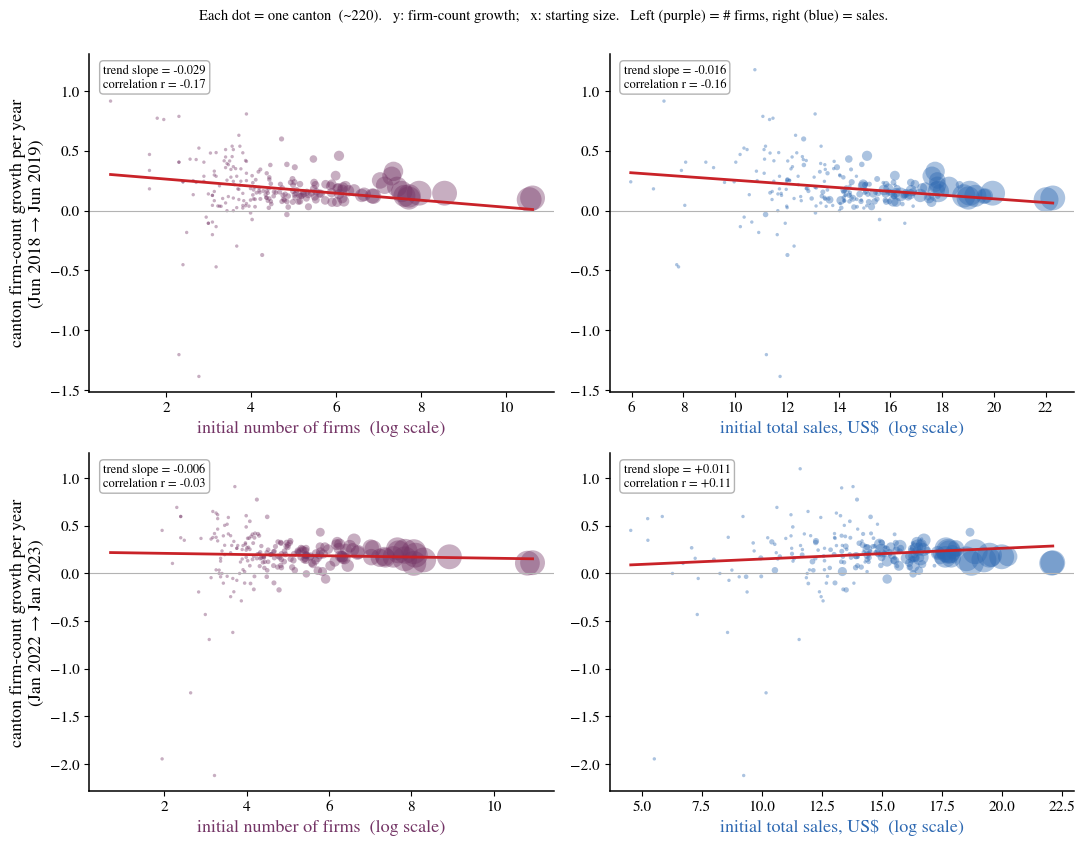

saved -> den_gibrat_scatter_province.png


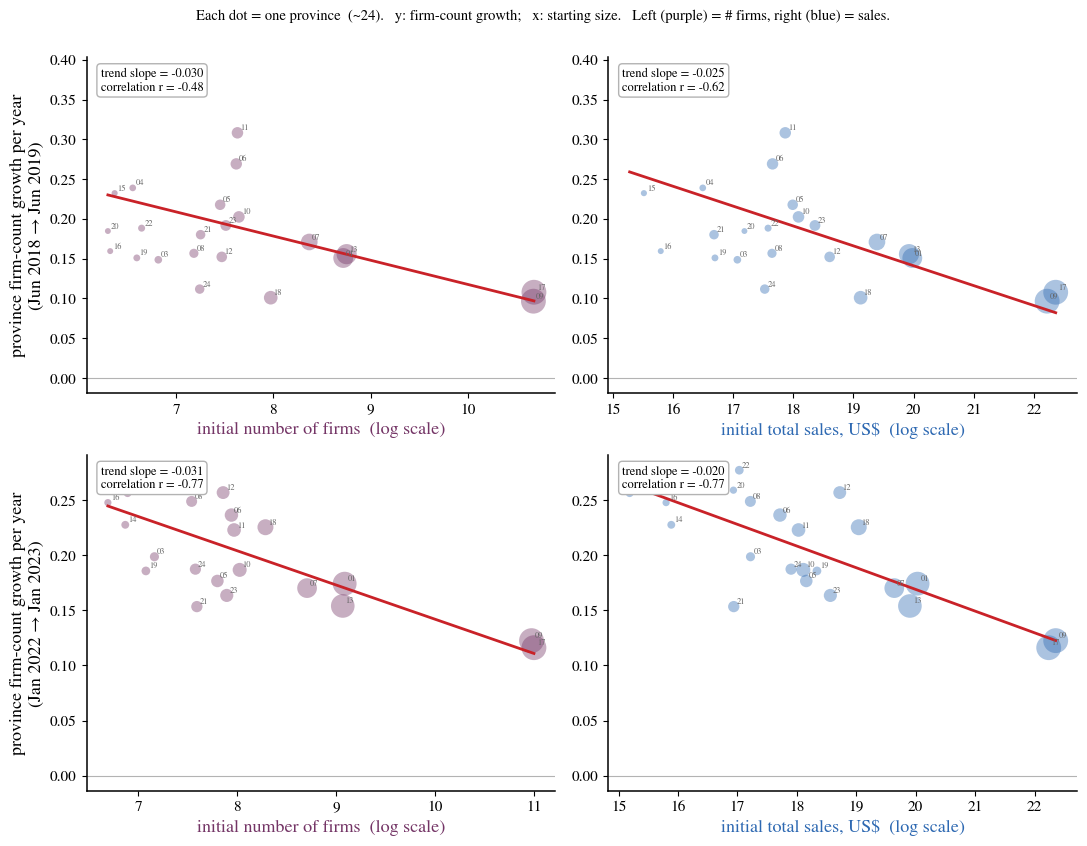

In [8]:
# ==============================================================================
# THE SAME SCATTER AT COARSER GEOGRAPHIES -- canton (4-digit) and province (2).
# ------------------------------------------------------------------------------
# Roll (parish, month) firms & sales up to each DPA prefix and repeat, one figure
# per level. The convergence STRENGTHENS as the geography coarsens: still weak at
# canton (|r| ~ 0.1, like parish), decisive only between provinces (|r| 0.5-0.8)
# -- exactly the multiscale selection profile (parish-within ~0, canton-within
# small, between-province dominant). Reuses _mon / WINS from the parish cell.
# ==============================================================================
AGG_LEVELS = [("canton", 4), ("province", 2)]          # (name, DPA prefix width)


def agg_units(prefix_w, y0, mo0, y1, mo1):
    """Per-unit initial firm count, initial log sales, annualised firm-count
    growth, and DPA code, aggregating parishes up to the given prefix width."""
    t = _mon.copy()
    t["u"] = t["cod_parr"].astype(str).str[:prefix_w]
    um = t.groupby(["u", "year", "mes_i"], as_index=False).agg(
        firms=("firms", "sum"), sales=("sales", "sum"))

    def cell(y, mo):
        d = um[(um.year == y) & (um.mes_i == mo)]
        return d.set_index("u")[["firms", "sales"]]

    a, b = cell(y0, mo0), cell(y1, mo1)
    ix = a.index.intersection(b.index)
    a, b = a.loc[ix], b.loc[ix]
    ok = (a.firms > 0) & (b.firms > 0) & (a.sales > 0) & (b.sales > 0)
    a, b = a[ok], b[ok]
    yrs = (y1 - y0) + (mo1 - mo0) / 12
    g = (np.log(b.firms.values) - np.log(a.firms.values)) / yrs
    return a.index.values, a.firms.values, np.log(a.sales.values), g


for level, pw in AGG_LEVELS:
    fig, axes = plt.subplots(len(WINS), 2, figsize=(11, 4.3 * len(WINS)))
    n_units = 0
    for r, (y0, mo0, y1, mo1) in enumerate(WINS):
        codes, n0, ls0, g = agg_units(pw, y0, mo0, y1, mo1)
        n_units = len(codes)
        sizes = np.clip(n0 / (30 if level == "province" else 8), 6, 320)
        wlab = f"{calendar.month_abbr[mo0]} {y0} \u2192 {calendar.month_abbr[mo1]} {y1}"
        for c, (x, xlab, is_den) in enumerate([
                (np.log(n0), "initial number of firms  (log scale)", True),
                (ls0,        "initial total sales, US$  (log scale)", False)]):
            ax = axes[r, c]
            ax.axhline(0, color="0.7", lw=0.8)
            ax.scatter(x, g, s=sizes, alpha=0.40, edgecolor="none",
                       color=style.PURPLE if is_den else style.BLUE)
            if n_units <= 30:                          # label points only if uncluttered
                for xi, gi, cd in zip(x, g, codes):
                    ax.annotate(cd, (xi, gi), fontsize=6, color="0.4",
                                xytext=(2, 2), textcoords="offset points")
            b1, b0 = np.polyfit(x, g, 1)
            xg = np.linspace(x.min(), x.max(), 50)
            ax.plot(xg, b0 + b1 * xg, color=style.RED, lw=2)
            ax.text(0.03, 0.97, f"trend slope = {b1:+.3f}\ncorrelation r = {np.corrcoef(x, g)[0,1]:+.2f}",
                    transform=ax.transAxes, va="top", fontsize=9,
                    bbox=dict(boxstyle="round", fc="white", ec="0.7"))
            ax.set_xlabel(xlab, color=style.PURPLE if is_den else style.BLUE)
            if c == 0:
                ax.set_ylabel(f"{level} firm-count growth per year\n({wlab})")
            for s in ("top", "right"):
                ax.spines[s].set_visible(False)
    verdict = ("a clear downward slope: smaller units grow faster (convergence)."
               if level == "province"
               else "still a flat cloud: growth barely depends on size (like parishes).")
    fig.suptitle(f"Each dot = one {level}  (~{n_units}).   y: firm-count growth;   "
                 f"x: starting size.   Left (purple) = # firms, right (blue) = sales.\n", fontsize=10.5)
    fig.tight_layout()
    fig.savefig(PLOTS_DIR / f"den_gibrat_scatter_{level}.png", dpi=200, bbox_inches="tight")
    fig.savefig(PLOTS_DIR / f"den_gibrat_scatter_{level}.pdf", bbox_inches="tight")
    print(f"saved -> den_gibrat_scatter_{level}.png")
    plt.show()


## Formal β-convergence regression (province tier), metro cores flagged

Barro-style cross-province regression of annualised firm-count growth on initial size: $g_i=\alpha+\beta\ln n_{i,0}+\varepsilon_i$, **$\beta<0 \Rightarrow$ convergence**. Three specifications per window: **all** 24 provinces; **+metro dummy** (β controlling for a Quito/Guayaquil indicator, codes 17 & 09); **ex-metro** (the 22 non-metro provinces). β is essentially unchanged across the three ⇒ the convergence is a **broad regional** phenomenon, not an artifact of the two big cities — and it vanishes/inverts in the COVID-onset window, matching the β-over-time plot.

In [9]:
# ==============================================================================
# FORMAL beta-CONVERGENCE REGRESSION (province tier), metro cores flagged.
# ------------------------------------------------------------------------------
# g_i = alpha + beta*ln(n_i0) + eps ;  beta < 0 = convergence. Three specs per
# window: all 24 / +metro dummy (17,09) / ex-metro (22). statsmodels OLS,
# SE in parentheses, ***/**/* = p < .01/.05/.10.
# ==============================================================================
import statsmodels.api as sm
METRO = ["17", "09"]                            # Pichincha/Quito, Guayas/Guayaquil


def prov_window(y0, mo0, y1, mo1):
    a, b = _prov_cell(y0, mo0), _prov_cell(y1, mo1)
    ix = a.index.intersection(b.index)
    a, b = a.loc[ix], b.loc[ix]
    ok = (a.firms > 0) & (b.firms > 0) & (a.sales > 0)
    a, b = a[ok], b[ok]
    yrs = (y1 - y0) + (mo1 - mo0) / 12
    g = (np.log(b.firms.values) - np.log(a.firms.values)) / yrs
    return pd.DataFrame({"g": g, "ln_n": np.log(a.firms.values),
                         "metro": np.isin(a.index.values, METRO).astype(float)})


def _b(model):
    beta, se, p = model.params["ln_n"], model.bse["ln_n"], model.pvalues["ln_n"]
    star = "***" if p < .01 else "**" if p < .05 else "*" if p < .1 else ""
    return f"{beta:+.3f} ({se:.3f}){star}"


WINREG = [(2018, 6, 2019, 6, "pre-COVID"), (2019, 4, 2020, 4, "COVID onset"),
          (2020, 4, 2021, 4, "rebound"), (2017, 1, 2023, 1, "full span")]
print(f"{'window':27s} {'beta all':>16s} {'beta +metroDum':>16s} {'beta ex-metro':>16s}  R2")
print("-" * 84)
full_beta = None
for y0, mo0, y1, mo1, tag in WINREG:
    d = prov_window(y0, mo0, y1, mo1)
    m_all = sm.OLS(d["g"], sm.add_constant(d[["ln_n"]])).fit()
    m_dum = sm.OLS(d["g"], sm.add_constant(d[["ln_n", "metro"]])).fit()
    dex = d[d.metro == 0]
    m_ex = sm.OLS(dex["g"], sm.add_constant(dex[["ln_n"]])).fit()
    print(f"{tag + f' {y0}M{mo0:02d}->{y1}M{mo1:02d}':27s} "
          f"{_b(m_all):>16s} {_b(m_dum):>16s} {_b(m_ex):>16s}  {m_all.rsquared:.2f}")
    if tag == "full span":
        full_beta = m_all.params["ln_n"]
print("-" * 84)
print("beta = annual firm-count growth on initial ln(firm count); beta<0 = convergence.")
if full_beta is not None and full_beta < 0:
    print(f"full-span convergence speed lambda = {-full_beta:.3f}/yr  ->  "
          f"half-life ln2/lambda ~ {np.log(2) / -full_beta:.0f} yr.")


window                              beta all   beta +metroDum    beta ex-metro  R2
------------------------------------------------------------------------------------
pre-COVID 2018M06->2019M06  -0.030 (0.012)**   -0.033 (0.020)   -0.033 (0.020)  0.23
COVID onset 2019M04->2020M04   +0.010 (0.009)   +0.011 (0.015)   +0.011 (0.015)  0.06
rebound 2020M04->2021M04    -0.021 (0.008)** -0.030 (0.014)**  -0.030 (0.015)*  0.22
full span 2017M01->2023M01  -0.012 (0.002)*** -0.015 (0.004)*** -0.015 (0.004)***  0.59
------------------------------------------------------------------------------------
beta = annual firm-count growth on initial ln(firm count); beta<0 = convergence.
full-span convergence speed lambda = 0.012/yr  ->  half-life ln2/lambda ~ 56 yr.


## Panel β-convergence — all windows pooled, fixed effects, clustered SEs

The per-window regressions above are each only $n=24$. Pooling **all 72 rolling windows** into a province panel gives power and lets us strip confounds:

$$g_{i,t}=\beta\,\ln n_{i,t_0}+\underbrace{a_i}_{\text{province FE}}+\underbrace{\tau_t}_{\text{time FE}}+\varepsilon_{i,t}.$$

- **Province FE** $a_i$ make this *conditional* convergence — each province toward its **own** steady state, absorbing fixed size/geography differences.
- **Time FE** $\tau_t$ absorb shocks common to all provinces in a window (the whole COVID episode included), so β is the cross-province size–growth link net of aggregate swings.
- **SEs clustered by province** (only 24 clusters, so the stars are descriptive). Spec (4) drops the COVID-straddling windows as a robustness check.

**Reading the output:** specs (1)–(2) estimate *cross-province absolute* convergence — β ≈ −0.01/yr, matching the cross-section, i.e. slow (half-life ~decades). Specs (3)–(4) add province FE, which changes the question to *within-province mean reversion* and is mechanically biased toward a large negative β by the overlapping rolling windows — so their β ≈ −0.4 is **not** a valid convergence speed, only a robust confirmation of the negative sign. The province-clustered SEs are what absorb the heavy serial correlation the overlapping windows create.

In [10]:
# ==============================================================================
# PANEL beta-CONVERGENCE (province tier) -- all rolling windows pooled, FE + clustered SE.
# ------------------------------------------------------------------------------
# Stack every (province, rolling-window) obs and estimate
#     g_{i,t} = beta * ln(n_{i,t0}) + [province FE] + [time FE] + e_{i,t}.
# Province FE => conditional convergence (each to its OWN steady state); time FE
# strip shocks common to all provinces in a window (incl. COVID). SE clustered by
# province. Reuses _prov_cell from the beta-over-time cell.
# ==============================================================================
import statsmodels.formula.api as smf

covid_ends = {f"{y}M{mo:02d}" for y, mo in
              [(2020, m) for m in range(4, 13)] + [(2021, m) for m in range(1, 5)]}

recs = []
for y0 in range(2017, 2023):
    for mo0 in range(1, 13):
        a, b = _prov_cell(y0, mo0), _prov_cell(y0 + 1, mo0)
        ix = a.index.intersection(b.index)
        a, b = a.loc[ix], b.loc[ix]
        ok = (a.firms > 0) & (b.firms > 0)
        a, b = a[ok], b[ok]
        g = np.log(b.firms.values) - np.log(a.firms.values)     # per yr (elapsed = 1)
        win = f"{y0 + 1}M{mo0:02d}"
        for code, gi, n0 in zip(a.index.values, g, a.firms.values):
            recs.append((code, win, gi, np.log(n0), win in covid_ends))
pan = pd.DataFrame(recs, columns=["prov", "win", "g", "ln_n", "covid"])
print(f"panel: {len(pan)} province-window observations "
      f"({pan.prov.nunique()} provinces x {pan.win.nunique()} windows)\n")


def fit_clus(formula, data):
    return smf.ols(formula, data=data).fit(
        cov_type="cluster", cov_kwds={"groups": data["prov"]})


SPECS = [
    ("(1) pooled, no FE  [absolute]",      "g ~ ln_n",                    pan),
    ("(2) + time (window) FE",             "g ~ ln_n + C(win)",           pan),
    ("(3) + province & time FE",           "g ~ ln_n + C(prov) + C(win)", pan),
    ("(4) two-way FE, drop COVID windows", "g ~ ln_n + C(prov) + C(win)", pan[~pan.covid]),
]
print(f"{'specification':38s} {'beta (clustered SE)':>22s}   n    R2")
print("-" * 76)
for name, f, d in SPECS:
    m = fit_clus(f, d)
    b, se, p = m.params["ln_n"], m.bse["ln_n"], m.pvalues["ln_n"]
    star = "***" if p < .01 else "**" if p < .05 else "*" if p < .1 else ""
    print(f"{name:38s} {b:+.4f} ({se:.4f}){star:3s}  {int(m.nobs):4d}  {m.rsquared:.2f}")
print("-" * 76)
print("beta < 0 = convergence (small provinces grow their firm count faster).")
print("READ (1)-(2): cross-province ABSOLUTE convergence ~ -0.01/yr (slow; matches")
print("  the cross-section). (3)-(4) add province FE -> WITHIN-province mean reversion,")
print("  a different object, biased down by the rolling-window overlap: the -0.4 is NOT")
print("  a valid speed, only a robust negative sign. Clustered SEs handle the overlap.")


panel: 1728 province-window observations (24 provinces x 72 windows)

specification                             beta (clustered SE)   n    R2
----------------------------------------------------------------------------
(1) pooled, no FE  [absolute]          -0.0101 (0.0024)***  1728  0.03
(2) + time (window) FE                 -0.0086 (0.0021)***  1728  0.63
(3) + province & time FE               -0.4085 (0.0601)***  1728  0.73
(4) two-way FE, drop COVID windows     -0.3194 (0.0517)***  1416  0.70
----------------------------------------------------------------------------
beta < 0 = convergence (small provinces grow their firm count faster).
READ (1)-(2): cross-province ABSOLUTE convergence ~ -0.01/yr (slow; matches
  the cross-section). (3)-(4) add province FE -> WITHIN-province mean reversion,
  a different object, biased down by the rolling-window overlap: the -0.4 is NOT
  a valid speed, only a robust negative sign. Clustered SEs handle the overlap.


## How to read the numbers — units

Every term obeys the Price identity **Δ trait = selection + transmission**, and every value is a **per-year** rate. Because each point is a rolling 12-month window (same calendar month a year apart), **seasonality cancels** and the elapsed time is exactly 1 year — so the numbers are honest annual growth rates with none of the ×12 blow-up that ruined the consecutive-month version. For $|\text{value}|\lesssim0.1$, log points ≈ %; larger moves convert exactly with $e^x-1$ (the COVID trough transmission ≈ $-0.62$ ⇒ $e^{-0.62}-1\approx-46\%$ real sales year-over-year). **Dating:** a point at 'Apr 20' is the change from Apr 2019 to Apr 2020. To change the horizon (e.g. rolling quarters), set `WINDOW_HORIZON` in `run_ecuador_price_decomposition_master.py` and re-run.

# Summary — Gibrat's law, spatial scale, and what it means for Ecuador

### 1. The mathematical framework
**Gibrat's law of proportionate growth:** a unit's growth *rate* is independent of its *size*. With firm count $n$,
$$n_{t+1}=n_t\,(1+g_t),\qquad g_t \perp n_t \;\Longleftrightarrow\; \mathbb{E}[\Delta\ln n \mid n]=\text{const}.$$
Test it as a **convergence regression** $\;\Delta\ln n_i=\alpha+\beta\,\ln n_{i,0}+\varepsilon_i$:


| | meaning |
|---|---|
| $\beta=0$ | **Gibrat** — size today says nothing about growth (scale-free) |
| $\beta<0$ | **convergence** — small grow faster, the size distribution compresses |
| $\beta>0$ | **divergence** — the big get bigger, concentration rises |

Pure Gibrat drives the size distribution toward **log-normal** — and indeed Ecuador's log-sales *level* is ≈ log-normal while its growth rates are fat-tailed, the classic Gibrat signature.

### 2. Selection *is* the departure from Gibrat
The density-path selection is
$$\text{selection}=\frac{\operatorname{Cov}_w(\Delta\ln n,\;n)}{\mu},\qquad \mu=\tfrac{1}{N}\textstyle\sum_j n_j^2\ \text{(experienced density)}.$$
The numerator $\operatorname{Cov}(\text{growth},\text{size})$ is exactly the quantity Gibrat sets to zero. So **selection is the (firm-share-weighted, normalised) violation of Gibrat's law**: $\beta=0\Rightarrow$ selection $=0$; $\beta<0\Rightarrow$ selection $<0$ (dispersion of the firm mass).

### 3. Why selection is only visible at the coarse scale
Fitting $\beta$ at the three nested tiers (scatters + panel above):

| scale | $\beta$ | Gibrat? | selection contribution |
|---|---|---|---|
| parish (within canton) | ≈ 0 | **holds** | ≈ 0 (slightly +) |
| canton (within province) | ≈ 0 | ~holds | small − |
| **province (between)** | **−0.012 to −0.03** | **fails** | **dominant −** (86%) |

So firm dynamics are **scale-free locally but converging regionally**. All the selection signal is the *between-province* breakdown of Gibrat; the fine scales obey it. A single pooled parish regression would conclude 'Gibrat, no selection' and **miss the effect entirely** — the multiscale decomposition's job is precisely to find the one tier where the law breaks.

### 4. Why this matters in the Ecuadorian context
- **Extreme concentration.** Quito (17) and Guayaquil (09) alone hold about half the formal firms; experienced density $\mu\approx20{,}500$ vs a plain mean of ~160. The 'average firm' sits in a very large parish.
- **Convergence is real but glacial.** Between provinces $\beta\approx-0.012$ ⇒ a **half-life of ~56 years**. Left to itself, the spatial concentration of the formal economy erodes only over generations — the periphery *is* catching up in firm formation, but extremely slowly.
- **No local rebalancing force.** Within provinces/cantons, growth is Gibrat: firms do **not** preferentially appear in smaller local units.
- **Shocks re-concentrate.** COVID flipped even the coarse convergence to *divergence* ($\beta>0$) — the metros were more resilient, so the crisis temporarily reconcentrated formal activity.
- **Policy read.** Spatial decentralisation of Ecuador's formal economy will not occur at a useful pace on its own, and the *only* margin where reallocation naturally happens is between provinces. Decentralisation policy should target that between-province margin and expect to work against both slow natural convergence and shock-driven re-concentration.

In [11]:
import numpy as np

(np.exp(0.04)-1)


np.float64(0.04081077419238821)

## Correlation analysis of the decomposition terms — math and how to read it

Each rolling YoY window $t = 1,\dots,72$ (dated at its end month) yields the five numbers plotted above as time series — the three nested selection scales, their total, and transmission:

$$
\underbrace{S_{\mathrm{prov}}(t)}_{\text{between provinces}}
+ \underbrace{S_{\mathrm{cant}}(t)}_{\text{cantons w/ province}}
+ \underbrace{S_{\mathrm{par}}(t)}_{\text{parishes w/ canton}}
= S(t),
\qquad
\Delta\bar z(t) = S(t) + T(t).
$$

The cells below treat these five series as data in their own right and ask how they co-move.

**Pearson correlation.** For two series $x_t, y_t$ over $n$ windows,

$$
r_{xy} \;=\; \frac{\sum_t (x_t-\bar x)(y_t-\bar y)}
{\sqrt{\sum_t(x_t-\bar x)^2}\,\sqrt{\sum_t(y_t-\bar y)^2}} \;\in\; [-1,1].
$$

Between two selection scales, $r>0$ says the sorting forces strengthen and weaken **together** — one spatial process expressed at two resolutions; $r<0$ says the scales **trade off** — months that push one way at the coarse scale push the other way at the fine scale. Between $S$ and $T$, $r<0$ says reallocation subtracts most exactly when within-region growth adds most.

**Rolling correlation.** The same $r$ over a moving window of the last $W$ months, plotted at the window's end month. A full-sample $r$ can average a regime change away; the rolling version **dates** it.

**Autocorrelation (ACF).** $\rho_x(k)=\operatorname{corr}(x_t,\,x_{t-k})$: how much a term remembers itself $k$ months back — persistence vs month-to-month noise.

**Cross-correlation (CCF).** $\rho_{TS}(k)=\operatorname{corr}(T_t,\, S_{t+k})$. A peak at $k>0$ says transmission **leads** selection by $k$ months; at $k<0$, selection leads; at $k=0$ they move within the same window.

Two caveats govern how much to trust any of these numbers:

1. **Overlap.** Adjacent rolling-YoY windows share 11 of their 12 months, so every series is mechanically smooth: high ACF at small lags is guaranteed (roughly an 11-month moving average), and the effective number of independent observations is closer to the 6 distinct years than to $n=72$. The $\pm 2/\sqrt{n}$ bands drawn below are therefore **optimistic** — treat them as a lower bar, not a test. The antidote is the **first-difference** correlation, $\Delta x_t = x_t - x_{t-1}$: what changes from $t-1$ to $t$ is only the month that enters and the month that drops out, so a correlation that survives differencing is not an artifact of the overlap.
2. **Adding-up.** $S_{\mathrm{prov}}+S_{\mathrm{cant}}+S_{\mathrm{par}}=S$ **by construction**, so each component is mechanically tilted toward positive correlation with the total, and the highest-variance component dominates its $r$ with $S$. The informative entries are the correlations **between** components — those are unconstrained.


saved -> monthly_corr_matrix_den.png


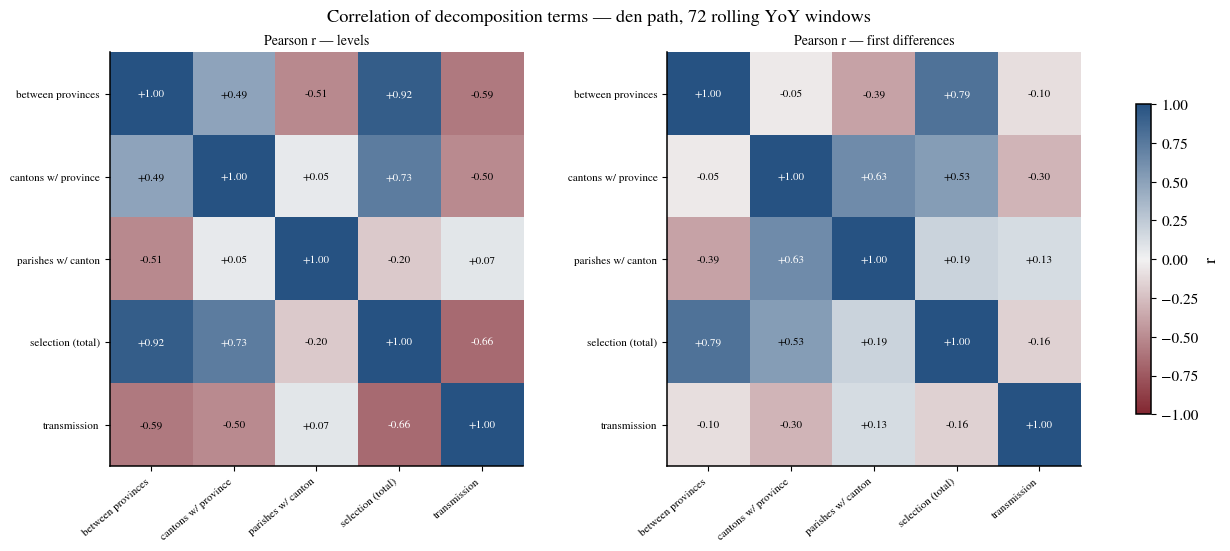


                                            full sample  before 2022M10  2022M10 onward  excl. COVID band
cantons w/ province  ~  parishes w/ canton         0.05            0.77           -0.40             -0.24
between provinces  ~  cantons w/ province          0.49            0.27            0.68              0.40
between provinces  ~  parishes w/ canton          -0.51            0.07           -0.92             -0.71
selection (total)  ~  transmission                -0.66           -0.59           -0.89             -0.52
(n windows)                                       72.00           57.00           15.00             59.00


In [12]:
# ==============================================================================
# CORRELATION STRUCTURE -- how the decomposition terms co-move
# ------------------------------------------------------------------------------
# Five monthly series: the three nested selection scales, their total, and
# transmission. Correlations are shown on LEVELS and on FIRST DIFFERENCES:
# adjacent rolling-YoY windows share 11 of their 12 months, so levels are
# mechanically smooth; differencing keeps only what each new month adds, and a
# correlation that survives it is not an artifact of the overlap.
# The printed table re-estimates the headline pairs on sub-samples: before and
# after the Oct-2022 within-canton flip, and with the COVID band removed.
# ==============================================================================
SERIES = {
    "between provinces":   ts["sel_between_provinces"],
    "cantons w/ province": ts["sel_canton_within_province"],
    "parishes w/ canton":  ts["sel_parish_within_canton"],
    "selection (total)":   ts["selection_total"],
    "transmission":        ts["transmission"],
}
X = pd.DataFrame(SERIES)
BREAK = "2022M10"       # the within-canton flip month (pop-path spike cells)
brk = int(ts.index[ts["final_period"] == BREAK][0])
in_covid = ts.index.isin(range(covid_pos, covid_end + 1))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.4), constrained_layout=True)
for ax, mat, title in [(axes[0], X.corr(), "levels"),
                       (axes[1], X.diff().corr(), "first differences")]:
    im = ax.imshow(mat, vmin=-1, vmax=1, cmap=style.DIVERGING)
    ax.set_xticks(range(5)); ax.set_yticks(range(5))
    ax.set_xticklabels(mat.columns, rotation=40, ha="right", fontsize=8)
    ax.set_yticklabels(mat.columns, fontsize=8)
    for i in range(5):
        for j in range(5):
            v = mat.iloc[i, j]
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(v) > 0.6 else "black")
    ax.set_title(f"Pearson r — {title}", fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.75, label="r")
fig.suptitle(f"Correlation of decomposition terms — {PATH} path, {len(X)} rolling YoY windows")
fig.savefig(PLOTS_DIR / f"monthly_corr_matrix_{PATH}.png", dpi=200, bbox_inches="tight")
print(f"saved -> monthly_corr_matrix_{PATH}.png")
plt.show()

# headline pairs, re-estimated on sub-samples
PAIRS = [("cantons w/ province", "parishes w/ canton"),
         ("between provinces",   "cantons w/ province"),
         ("between provinces",   "parishes w/ canton"),
         ("selection (total)",   "transmission")]
SPLITS = {"full sample":      X,
          f"before {BREAK}":  X.iloc[:brk],
          f"{BREAK} onward":  X.iloc[brk:],
          "excl. COVID band": X[~in_covid]}
table = pd.DataFrame({name: {f"{a}  ~  {b}": Xs[a].corr(Xs[b]) for a, b in PAIRS}
                      for name, Xs in SPLITS.items()}).round(2)
table.loc["(n windows)"] = [len(Xs) for Xs in SPLITS.values()]
print(); print(table.to_string())

saved -> monthly_rolling_corr_den.png


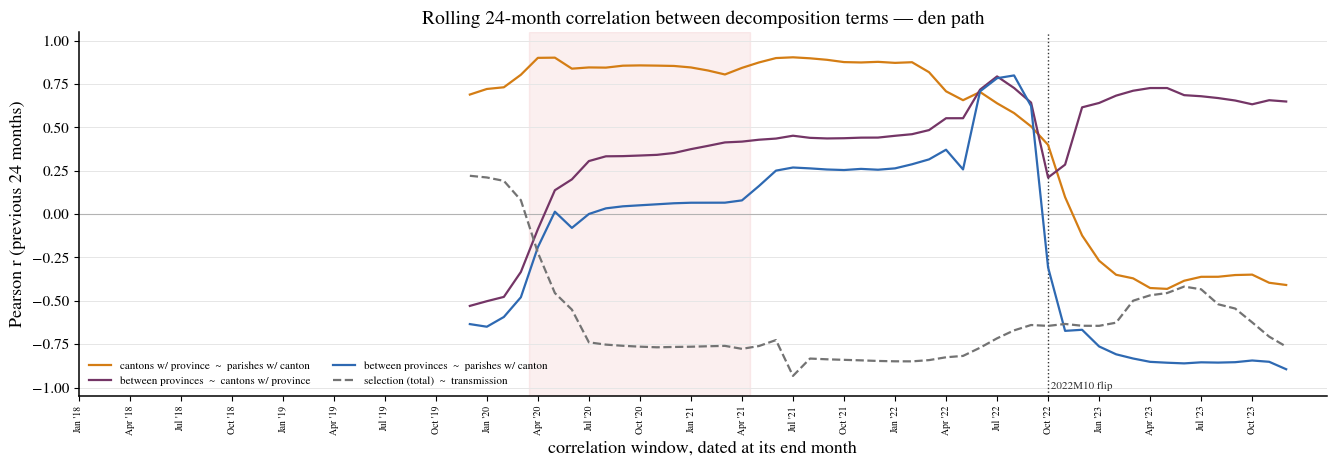

cantons~parishes rolling-24 r:  max +0.90 at Jul '21,  last -0.41,  first negative at Dec '22


In [13]:
# rolling correlation -- Pearson r over a moving W-month window, dated at its
# END month, so a value plotted at month t summarises the previous W months.
# A full-sample r can hide a regime change; this cell dates WHEN each
# co-movement holds and when it breaks.
W = 24                  # months per correlation window
ROLL_PAIRS = [
    ("cantons w/ province", "parishes w/ canton",  style.ORANGE),
    ("between provinces",   "cantons w/ province", style.PURPLE),
    ("between provinces",   "parishes w/ canton",  style.BLUE),
    ("selection (total)",   "transmission",        "0.45"),
]
fig, ax = plt.subplots(figsize=(13.5, 4.8))
ax.axhline(0, color="0.7", lw=0.8)
ax.axvspan(covid_pos - 0.5, covid_end + 0.5, color=style.RED, alpha=0.07)
ax.axvline(brk, color="0.2", lw=1.0, ls=":")
ax.text(brk, -1.02, f" {BREAK} flip", fontsize=8, color="0.2", va="bottom")
for a, b, color in ROLL_PAIRS:
    rc = X[a].rolling(W).corr(X[b])
    ls = "--" if a == "selection (total)" else "-"
    ax.plot(xs, rc, lw=1.6, color=color, ls=ls, label=f"{a}  ~  {b}")
ax.set_ylim(-1.05, 1.05)
ax.set_xticks(xs[::STRIDE]); ax.set_xticklabels(labels[::STRIDE], rotation=90, fontsize=7)
ax.set_ylabel(f"Pearson r (previous {W} months)")
ax.set_xlabel("correlation window, dated at its end month")
ax.set_title(f"Rolling {W}-month correlation between decomposition terms — {PATH} path")
ax.grid(axis="y", color="0.9", lw=0.7)
for s in ("top", "right"): ax.spines[s].set_visible(False)
ax.legend(loc="lower left", frameon=False, fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"monthly_rolling_corr_{PATH}.png", dpi=200, bbox_inches="tight")
fig.savefig(PLOTS_DIR / f"monthly_rolling_corr_{PATH}.pdf", bbox_inches="tight")
print(f"saved -> monthly_rolling_corr_{PATH}.png")
plt.show()

rc = X["cantons w/ province"].rolling(W).corr(X["parishes w/ canton"]).dropna()
neg = rc[rc < 0]
print(f"cantons~parishes rolling-{W} r:  max {rc.max():+.2f} at "
      f"{month_label(ts['final_period'][rc.idxmax()])},  last {rc.iloc[-1]:+.2f}"
      + (f",  first negative at {month_label(ts['final_period'][neg.index[0]])}"
         if len(neg) else ",  never negative"))

saved -> monthly_acf_ccf_den.png


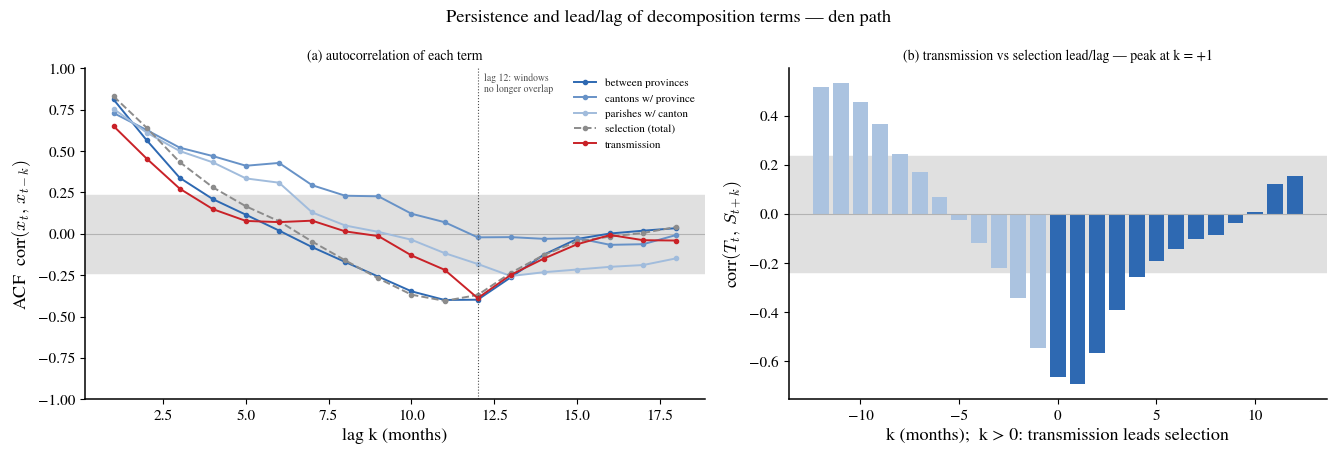

In [14]:
# autocorrelation and lead/lag structure.
# (a) ACF of each term. Adjacent YoY windows share 11 months, so high ACF at
#     small lags is partly mechanical -- read it RELATIVELY: which terms stay
#     persistent past lag ~6, and what happens at lag 12, where the two windows
#     no longer overlap at all (base effects show up as negative ACF there).
# (b) Cross-correlation corr(T_t, S_{t+k}): does transmission lead selection
#     (peak at k > 0), lag it (k < 0), or move with it (peak at k = 0)?
# Shaded band: +-2/sqrt(n) -- an OPTIMISTIC null given the window overlap.
def acf(x, k):
    x = np.asarray(x, float); x = x - x.mean()
    return float((x[k:] * x[:-k]).sum() / (x * x).sum())

ACF_LAGS = range(1, 19)
CCF_LAGS = range(-12, 13)
SERIES_STYLE = [("between provinces",   style.BLUE, "-"),
                ("cantons w/ province", style.SCALE["canton"], "-"),
                ("parishes w/ canton",  style.SCALE["parish"], "-"),
                ("selection (total)",   "0.55",    "--"),
                ("transmission",        style.RED, "-")]
band = 2 / np.sqrt(len(X))

fig, (ax_a, ax_c) = plt.subplots(1, 2, figsize=(13.5, 4.6),
                                 gridspec_kw={"width_ratios": [1.15, 1]})
for ax in (ax_a, ax_c):
    ax.axhline(0, color="0.7", lw=0.8)
    ax.axhspan(-band, band, color="0.88", zorder=0)
    for s in ("top", "right"): ax.spines[s].set_visible(False)

for name, color, ls in SERIES_STYLE:
    ax_a.plot(list(ACF_LAGS), [acf(X[name], k) for k in ACF_LAGS],
              marker="o", ms=3, lw=1.4, color=color, ls=ls, label=name)
ax_a.axvline(12, color="0.3", lw=0.8, ls=":")
ax_a.text(12.2, 0.97, "lag 12: windows\nno longer overlap",
          fontsize=7, color="0.3", va="top")
ax_a.set_xlabel("lag k (months)")
ax_a.set_ylabel("ACF  corr$(x_t,\\,x_{t-k})$")
ax_a.set_title("(a) autocorrelation of each term", fontsize=10)
ax_a.set_ylim(-1, 1)
ax_a.legend(frameon=False, fontsize=8, loc="upper right")

ccf = [X["transmission"].corr(X["selection (total)"].shift(-k)) for k in CCF_LAGS]
kmax = list(CCF_LAGS)[int(np.argmax(np.abs(ccf)))]
ax_c.bar(list(CCF_LAGS), ccf,
         color=[style.BLUE if k >= 0 else style.tint(style.BLUE, 0.6) for k in CCF_LAGS])
ax_c.set_xlabel("k (months);  k > 0: transmission leads selection")
ax_c.set_ylabel("corr$(T_t,\\,S_{t+k})$")
ax_c.set_title(f"(b) transmission vs selection lead/lag — peak at k = {kmax:+d}",
               fontsize=10)
fig.suptitle(f"Persistence and lead/lag of decomposition terms — {PATH} path")
fig.tight_layout()
fig.savefig(PLOTS_DIR / f"monthly_acf_ccf_{PATH}.png", dpi=200, bbox_inches="tight")
print(f"saved -> monthly_acf_ccf_{PATH}.png")
plt.show()

## What the correlations say — den path

**Same late-2022 break as the pop path, in density units.** Cantons~parishes: **+0.77 before Oct 2022, −0.40 after**; the rolling 24-month correlation peaks at +0.90 (window ending mid-2021) and first goes negative in **Dec 2022**. Because the den path is built from firm counts alone, this confirms the break is about *where firms locate*, not about sales — the inc path shows no break at all. After the break, parishes-within-cantons opposes between-provinces at **−0.92**, while provinces~cantons tightens (+0.27 → +0.68): the finest scale flips against the whole hierarchy.

**The full-sample provinces~parishes anticorrelation (−0.51) is the multiscale convergence signature.** Even before the break, months when experienced density drifts up at the province scale tend to be months when it drifts down within cantons. This is the time-series counterpart of the β-convergence regressions above: fine-scale equalization (Gibrat-violating convergence within cantons) coexists with, and partially offsets, coarse-scale drift — which is how total den selection stays ≈ 0 while its components pull in opposite directions.

**Transmission leads selection by about a month — the only path with a lead.** The CCF peaks at k = +1 (−0.69, vs −0.66 at k = 0): windows with strong within-region firm-count growth are followed one month later by the most negative selection. Read cautiously — with 11-month-overlapping windows a ±1-month lead sits at the edge of resolution — but the sign is suggestive: entry booms come first, reallocation payback follows. And unlike the pop path, the trade-off is not just COVID: sel~trans is −0.66 overall and still −0.52 with the COVID band removed.

**Differencing flips one conclusion.** In levels provinces~cantons is +0.49, but in first differences it drops to −0.05 while cantons~parishes rises to +0.63: month-by-month news moves the two *sub-province* scales together and leaves the province scale on its own slow cycle (level ACF +0.81 at lag 1, turning ≈ −0.4 by lag 12 — year-later payback). The genuine high-frequency co-movement lives below the province tier.